# 5 — Visualización orientada a preguntas

Un gráfico no es el objetivo: es evidencia para responder una pregunta. En cada ejercicio primero escribí qué querés averiguar, luego construí la agregación y finalmente redactá una conclusión de dos o tres oraciones.

Este notebook se ejecuta manualmente **después** de que el Job termina correctamente; no forma parte del pipeline.

In [0]:
dbutils.widgets.text("student_id", "alumno01", "01 - Identificador")
dbutils.widgets.dropdown("scale", "small", ["test", "small", "demo"], "02 - Escala")

In [0]:
%run ../common/config

In [0]:
from pyspark.sql import functions as F
import matplotlib.pyplot as plt

catalog = spark.sql("SELECT current_catalog()").first()[0]
config = CourseConfig(catalog, dbutils.widgets.get("student_id"), dbutils.widgets.get("scale"))
daily = qualified_table(config, "gold_daily_sales")
risk = qualified_table(config, "gold_customer_risk")
batch = qualified_table(config, "gold_batch_summary")
for table in [daily, risk, batch]:
    assert spark.catalog.tableExists(table), f"Falta {table}. Ejecutá primero el Job completo."

## Ejemplo resuelto

**Pregunta:** ¿Qué categoría concentra el mayor monto vendido?

La agregación se hace con Spark. Sólo el resultado pequeño se convierte a Pandas para dibujarlo. Un gráfico de barras ordenado permite comparar categorías; un gráfico de torta haría más difícil comparar valores cercanos.

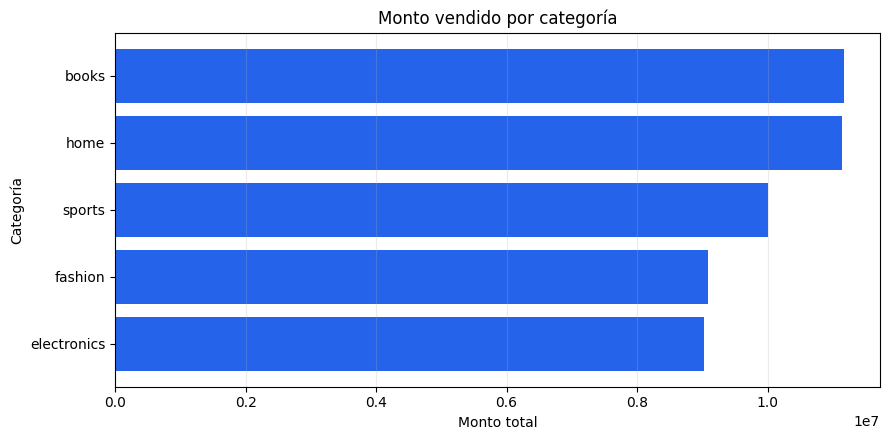

Respuesta: books es la categoría con mayor monto vendido (11,165,281.86).


In [0]:
category_sales = (spark.table(daily)
    .groupBy("category")
    .agg(F.sum("total_amount").alias("total_amount"))
    .orderBy(F.desc("total_amount")))

plot_data = category_sales.toPandas().sort_values("total_amount")
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(plot_data["category"], plot_data["total_amount"], color="#2563eb")
ax.set_title("Monto vendido por categoría")
ax.set_xlabel("Monto total")
ax.set_ylabel("Categoría")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

leader = category_sales.first()
print(f"Respuesta: {leader.category} es la categoría con mayor monto vendido ({leader.total_amount:,.2f}).")

## Consigna 1 — Evolución temporal

**Pregunta:** ¿Qué día tuvo el mayor monto vendido y ese día también fue el de mayor cantidad de transacciones?

Construí una visualización temporal que permita comparar ambas métricas sin ocultar sus unidades. Explicá si los dos máximos coinciden y qué implica que coincidan —o no— sobre el ticket promedio. Fuente sugerida: `gold_daily_sales`.

In [0]:
%pip install seaborn


Looking in indexes: [REDACTED]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


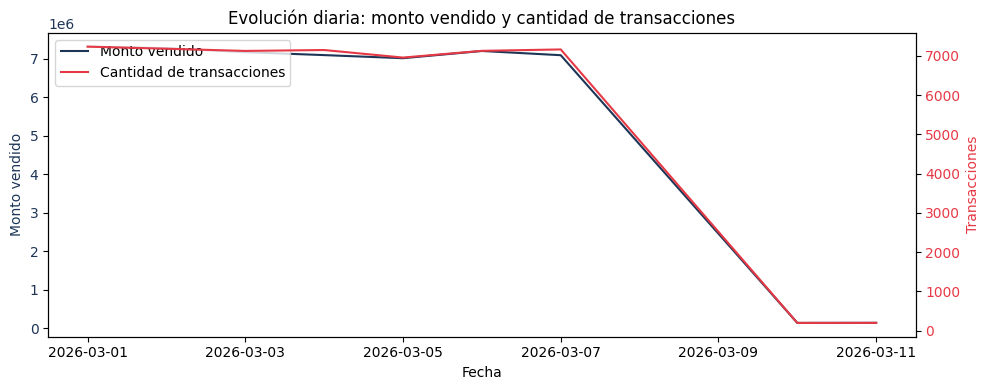

El día con mayor monto vendido (7,310,840.77) coincide con el de mayor cantidad de transacciones (7236), el 2026-03-01. Esto sugiere que el ticket promedio no tuvo un salto inusual ese día.


In [0]:
# Consigna 1 — Evolución temporal
# Agrego por sale_date y muestro monto y cantidad de transacciones.
daily_df = spark.table(daily)
result = (
    daily_df.groupBy("sale_date")
        .agg(
            F.sum("total_amount").alias("total_amount"),
            F.sum("transaction_count").alias("transaction_count")
        )
        .orderBy("sale_date")
)
plot_data = result.toPandas()
fig, ax1 = plt.subplots(figsize=(10, 4))
color1 = "#1d3557"
color2 = "#e63946"
ln1 = ax1.plot(plot_data["sale_date"], plot_data["total_amount"], color=color1, label="Monto vendido")
ax1.set_xlabel("Fecha")
ax1.set_ylabel("Monto vendido", color=color1)
ax1.tick_params(axis="y", labelcolor=color1)
ax2 = ax1.twinx()
ln2 = ax2.plot(plot_data["sale_date"], plot_data["transaction_count"], color=color2, label="Cantidad de transacciones")
ax2.set_ylabel("Transacciones", color=color2)
ax2.tick_params(axis="y", labelcolor=color2)
lns = ln1 + ln2
labs = [l.get_label() for l in lns]
ax1.legend(lns, labs, loc="upper left")
plt.title("Evolución diaria: monto vendido y cantidad de transacciones")
fig.tight_layout()
plt.show()

max_monto = plot_data.loc[plot_data["total_amount"].idxmax()]
max_tx = plot_data.loc[plot_data["transaction_count"].idxmax()]
if max_monto["sale_date"] == max_tx["sale_date"]:
    conclusion = f"El día con mayor monto vendido ({max_monto['total_amount']:,.2f}) coincide con el de mayor cantidad de transacciones ({int(max_tx['transaction_count'])}), el {max_monto['sale_date']}. Esto sugiere que el ticket promedio no tuvo un salto inusual ese día."
else:
    conclusion = f"El día con mayor monto vendido fue {max_monto['sale_date']} ({max_monto['total_amount']:,.2f}), mientras que el máximo en cantidad de transacciones fue el {max_tx['sale_date']} ({int(max_tx['transaction_count'])}). Esto implica que el ticket promedio varió significativamente entre días."
print(conclusion)

## Consigna 2 — Canal y fraude

**Pregunta:** ¿Qué canal de pago presenta la mayor tasa de fraude? ¿La conclusión se sostiene al considerar el número de transacciones de cada canal?

Mostrá tasa y volumen de manera legible. No compares sólo cantidades de fraude: calculá el denominador correcto. Fuente sugerida: `gold_daily_sales`.

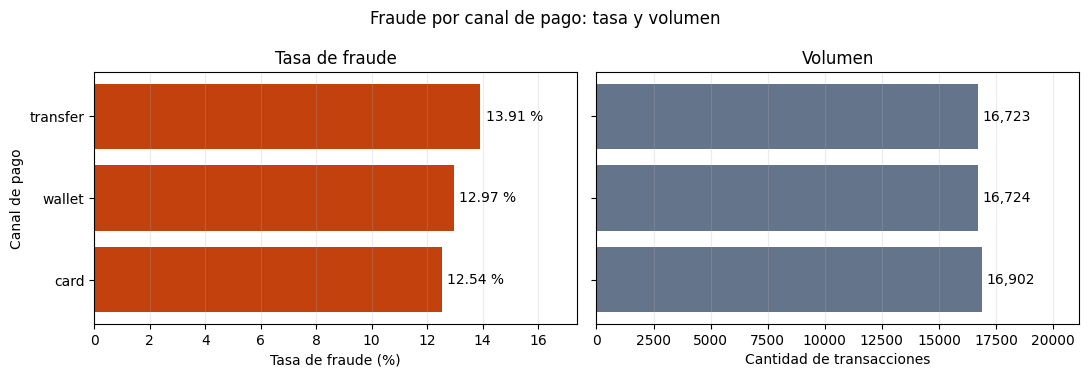

El canal con mayor tasa de fraude es transfer (13.91%). La conclusión se sostiene al considerar el volumen: los canales tienen una cantidad de transacciones muy parecida (entre 16,723 y 16,902, 1.1% de diferencia), así que la diferencia en la tasa no se explica por el tamaño de cada canal.


In [0]:
# Consigna 2 — Canal y fraude
# Tasa global = SUM(fraud_transactions) / SUM(transaction_count) por canal.
# No se promedia fraud_rate: cada fila de gold_daily_sales es un grupo de distinto tamaño.
channels = (
    daily_df.groupBy("payment_channel")
        .agg(
            F.sum("fraud_transactions").alias("fraud_transactions"),
            F.sum("transaction_count").alias("transaction_count")
        )
        .withColumn("fraud_rate", F.col("fraud_transactions") / F.col("transaction_count"))
        .orderBy(F.desc("fraud_rate"))
)
plot_data = channels.toPandas()
plot_data["fraud_rate"] = plot_data["fraud_rate"].astype(float)
plot_data = plot_data.sort_values("fraud_rate")  # en barras horizontales, el mayor queda arriba

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
ax1.barh(plot_data["payment_channel"], plot_data["fraud_rate"] * 100, color="#c2410c")
ax1.set_title("Tasa de fraude")
ax1.set_xlabel("Tasa de fraude (%)")
ax1.set_ylabel("Canal de pago")
ax1.set_xlim(0, plot_data["fraud_rate"].max() * 100 * 1.25)
for y, v in enumerate(plot_data["fraud_rate"] * 100):
    ax1.text(v + 0.2, y, f"{v:.2f} %", va="center")
ax2.barh(plot_data["payment_channel"], plot_data["transaction_count"], color="#64748b")
ax2.set_title("Volumen")
ax2.set_xlabel("Cantidad de transacciones")
ax2.set_xlim(0, plot_data["transaction_count"].max() * 1.25)
for y, v in enumerate(plot_data["transaction_count"]):
    ax2.text(v * 1.01, y, f"{int(v):,}", va="center")
for ax in (ax1, ax2):
    ax.grid(axis="x", alpha=0.25)
fig.suptitle("Fraude por canal de pago: tasa y volumen")
fig.tight_layout()
plt.show()

top = plot_data.iloc[-1]
vol_min, vol_max = plot_data["transaction_count"].min(), plot_data["transaction_count"].max()
spread = (vol_max - vol_min) / vol_max
conclusion = f"El canal con mayor tasa de fraude es {top['payment_channel']} ({top['fraud_rate']:.2%}). "
if spread < 0.10:
    conclusion += (f"La conclusión se sostiene al considerar el volumen: los canales tienen una cantidad de transacciones "
                   f"muy parecida (entre {int(vol_min):,} y {int(vol_max):,}, {spread:.1%} de diferencia), "
                   f"así que la diferencia en la tasa no se explica por el tamaño de cada canal.")
else:
    conclusion += (f"Los volúmenes difieren bastante (entre {int(vol_min):,} y {int(vol_max):,}); "
                   f"conviene leer la tasa junto con el volumen antes de concluir.")
print(conclusion)

## Consigna 3 — Concentración geográfica y de producto

**Pregunta:** ¿Qué combinación de país y categoría genera el mayor monto? ¿Existe una categoría dominante en todos los países o cambia según el mercado?

Elegí una visualización que permita comparar simultáneamente países y categorías. Justificá brevemente por qué ese tipo de gráfico es adecuado. Fuente sugerida: `gold_daily_sales`.

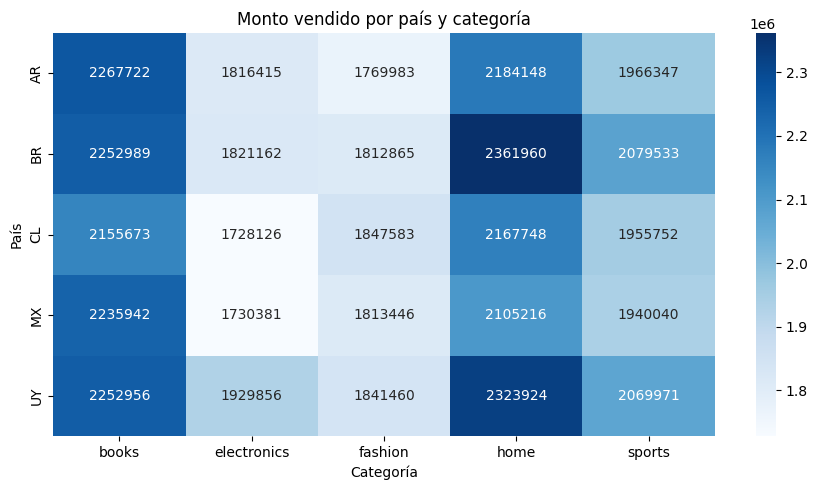

La combinación de mayor monto es BR + home (2,361,959.97). La categoría dominante varía entre países.


In [0]:
# Consigna 3 — Concentración geográfica y de producto
# Cruzo country y category, sumo monto y grafico como heatmap
combo = (
    daily_df.groupBy("country", "category")
      .agg(F.sum("total_amount").alias("total_amount"))
      .orderBy("country", "category")
)
plot_data = combo.toPandas().pivot(index="country", columns="category", values="total_amount").astype(float)
import seaborn as sns
fig, ax = plt.subplots(figsize=(9,5))
sns.heatmap(plot_data, annot=True, fmt=".0f", cmap="Blues", ax=ax)
plt.title("Monto vendido por país y categoría")
plt.xlabel("Categoría")
plt.ylabel("País")
plt.tight_layout()
plt.show()

maxcell = combo.orderBy(F.desc("total_amount")).first()
grouped = plot_data.idxmax(axis=1)
diff_cats = grouped.nunique() > 1
conclusion = f"La combinación de mayor monto es {maxcell.country} + {maxcell.category} ({maxcell.total_amount:,.2f}). "
if diff_cats:
    conclusion += "La categoría dominante varía entre países."
else:
    conclusion += f"La categoría dominante es la misma en todos los países: {grouped.mode()[0]}."
print(conclusion)


**Justificación del gráfico:** un mapa de calor país × categoría muestra las dos dimensiones a la vez. Leyendo cada fila se ve qué categoría lidera en cada país, y la intensidad permite ubicar la celda máxima de toda la matriz. Cada celda lleva su valor anotado, así que la lectura no depende solo del color.

## Consigna 4 — Calidad del pipeline

**Pregunta:** ¿Qué proporción de cada lote fue aceptada y rechazada? ¿El lote nuevo presenta una calidad diferente del lote inicial?

Compará lotes usando proporciones además de cantidades absolutas. Señalá cualquier limitación de comparar lotes de tamaños distintos. Fuente sugerida: `gold_batch_summary`.

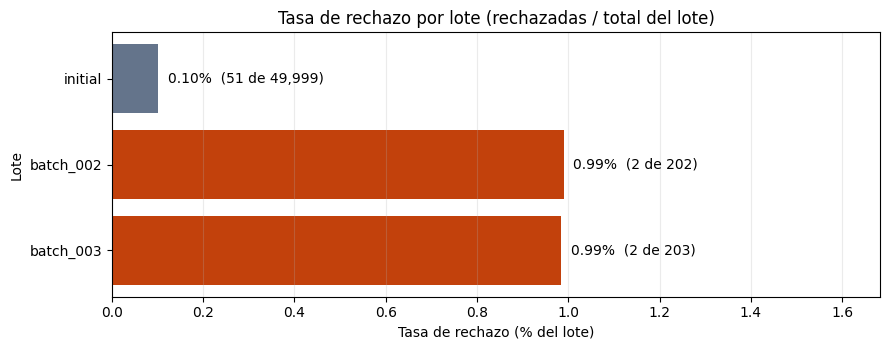

initial: 99.90% aceptadas, 0.10% rechazadas (51 de 49,999).
batch_002: 99.01% aceptadas, 0.99% rechazadas (2 de 202).
batch_003: 99.01% aceptadas, 0.99% rechazadas (2 de 203).
Los lotes nuevos tienen una tasa de rechazo unas 10 veces mayor que el inicial, pero eso no implica una peor calidad de origen: el generador inyecta 2 registros inválidos por lote, y en lotes de ~200 filas cada registro mueve la tasa medio punto. Con tamaños tan distintos, la tasa de los lotes chicos es muy sensible y conviene leerla junto con las cantidades absolutas.


In [0]:
# Consigna 4 — Calidad del pipeline
# Grafico la tasa de rechazo de cada lote: en barras apiladas al 100 % el segmento rechazado (~1 %) no se distingue.
batch_pd = (
    spark.table(batch)
        .withColumn("total", F.col("accepted_transactions") + F.col("rejected_transactions"))
        .withColumn("accepted_pct", F.col("accepted_transactions") / F.col("total"))
        .withColumn("rejected_pct", F.col("rejected_transactions") / F.col("total"))
        .select("source_batch_id", "accepted_transactions", "rejected_transactions", "total", "accepted_pct", "rejected_pct")
        .toPandas()
)
batch_pd[["accepted_pct", "rejected_pct"]] = batch_pd[["accepted_pct", "rejected_pct"]].astype(float)
order = sorted(batch_pd["source_batch_id"], key=lambda b: (b != "initial", b))  # initial primero, luego los lotes nuevos
batch_pd = batch_pd.set_index("source_batch_id").loc[order].reset_index()
plot = batch_pd.iloc[::-1]  # en barras horizontales, initial queda arriba

fig, ax = plt.subplots(figsize=(9, 3.6))
colors = ["#64748b" if b == "initial" else "#c2410c" for b in plot["source_batch_id"]]
ax.barh(plot["source_batch_id"], plot["rejected_pct"] * 100, color=colors)
for y, (_, r) in enumerate(plot.iterrows()):
    ax.text(r["rejected_pct"] * 100 + 0.02, y,
            f"{r['rejected_pct']:.2%}  ({int(r['rejected_transactions'])} de {int(r['total']):,})", va="center")
ax.set_xlim(0, plot["rejected_pct"].max() * 100 * 1.7)
ax.set_title("Tasa de rechazo por lote (rechazadas / total del lote)")
ax.set_xlabel("Tasa de rechazo (% del lote)")
ax.set_ylabel("Lote")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

for _, r in batch_pd.iterrows():
    print(f"{r['source_batch_id']}: {r['accepted_pct']:.2%} aceptadas, {r['rejected_pct']:.2%} rechazadas "
          f"({int(r['rejected_transactions'])} de {int(r['total']):,}).")
print("Los lotes nuevos tienen una tasa de rechazo unas 10 veces mayor que el inicial, pero eso no implica una peor "
      "calidad de origen: el generador inyecta 2 registros inválidos por lote, y en lotes de ~200 filas cada registro "
      "mueve la tasa medio punto. Con tamaños tan distintos, la tasa de los lotes chicos es muy sensible y conviene "
      "leerla junto con las cantidades absolutas.")

## Criterios de entrega

Para cada consigna entregá: (1) la transformación de datos, (2) un gráfico, y (3) una conclusión de dos o tres oraciones que responda explícitamente la pregunta.

Cada gráfico debe tener título informativo, ejes y unidades legibles, categorías ordenadas cuando corresponda y una elección de color que no sea la única forma de comunicar el significado. No conviertas una tabla Silver completa a Pandas: agregá primero con Spark y convertí sólo el resultado pequeño.